In [4]:
# This Python 3 environment comes with many helpful analytics libraries installed
# It is defined by the kaggle/python Docker image: https://github.com/kaggle/docker-python
# For example, here's several helpful packages to load

import numpy as np # linear algebra
import pandas as pd # data processing, CSV file I/O (e.g. pd.read_csv)

# Input data files are available in the read-only "../input/" directory
# For example, running this (by clicking run or pressing Shift+Enter) will list all files under the input directory

import os
for dirname, _, filenames in os.walk('/kaggle/input'):
    for filename in filenames:
        print(os.path.join(dirname, filename))

# You can write up to 20GB to the current directory (/kaggle/working/) that gets preserved as output when you create a version using "Save & Run All" 
# You can also write temporary files to /kaggle/temp/, but they won't be saved outside of the current session

# Use the kagglehub client library to attach Kaggle resources like competitions, datasets, and models to your session
# Learn more about kagglehub: https://github.com/Kaggle/kagglehub/blob/main/README.md

import kagglehub
# kagglehub.dataset_download('<owner>/<dataset-slug>')

/kaggle/input/datasets/mugishaoscar/customer-dataset/WA_Fn-UseC_-Telco-Customer-Churn.csv


reg no: 224005702

# Lab 1: Telco Customer Churn Exploratory Data Analysis
## Overview
The objective of this work is to clean, transform, and analyze a telecom customer dataset to uncover factors that drive customer attrition (Churn). i will map data features, clean missing information records, and visualize key relationship dimensions across customer demographics, subscribed services, and financial billing terms to capture actionable indicators.


In [6]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Assuming the data text is saved as a local CSV file 'Telco-Customer-Churn.csv'
df = pd.read_csv('/kaggle/input/datasets/mugishaoscar/customer-dataset/WA_Fn-UseC_-Telco-Customer-Churn.csv')
print("Dataset loaded successfully!")

Dataset loaded successfully!


from this cell  i have learned how to to load the data from the database 

In [7]:
# Display first 5 rows
print("--- DATASET HEAD ---")
display(df.head())

# Display last 5 rows
print("\n--- DATASET TAIL ---")
display(df.tail())


--- DATASET HEAD ---


,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,...,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,...,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,...,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes



--- DATASET TAIL ---


,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
7038,6840-RESVB,Male,0,Yes,Yes,24,Yes,Yes,DSL,Yes,...,Yes,Yes,Yes,Yes,One year,Yes,Mailed check,84.80,1990.5,No
7039,2234-XADUH,Female,0,Yes,Yes,72,Yes,Yes,Fiber optic,No,...,Yes,No,Yes,Yes,One year,Yes,Credit card (automatic),103.20,7362.9,No
7040,4801-JZAZL,Female,0,Yes,Yes,11,No,No phone service,DSL,Yes,...,No,No,No,No,Month-to-month,Yes,Electronic check,29.60,346.45,No
7041,8361-LTMKD,Male,1,Yes,No,4,Yes,Yes,Fiber optic,No,...,No,No,No,No,Month-to-month,Yes,Mailed check,74.40,306.6,Yes
7042,3186-AJIEK,Male,0,No,No,66,Yes,No,Fiber optic,Yes,...,Yes,Yes,Yes,Yes,Two year,Yes,Bank transfer (automatic),105.65,6844.5,No


from this cell i have seen that the head display the first five rows while the tail display the last five rows

In [8]:
# 1. Verify the unique values before mapping
print("Before mapping, unique Churn values:", df['Churn'].unique())

# 2. Convert categorical text 'Yes'/'No' to numerical binary 1/0
df['Churn'] = df['Churn'].map({'Yes': 1, 'No': 0})

# 3. Verify the change was successful
print("After mapping, unique Churn values: ", df['Churn'].unique())
print("\nFirst 5 rows of mapped data:")
display(df[['customerID', 'Churn']].head())


Before mapping, unique Churn values: ['No' 'Yes']
After mapping, unique Churn values:  [0 1]

First 5 rows of mapped data:


,customerID,Churn
0,7590-VHVEG,0
1,5575-GNVDE,0
2,3668-QPYBK,1
3,7795-CFOCW,0
4,9237-HQITU,1


The cell successfully transitions the text fields Yes and No inside the target variable column into strict numeric values of 1 and 0.

In [12]:
print("=== INITIAL DATATYPES ===")
print(df.dtypes)


# 2. Change the object column to the desired numeric type
# We strip any hidden trailing white spaces and coerce text fields to float values
df['TotalCharges'] = pd.to_numeric(df['TotalCharges'].astype(str).str.strip(), errors='coerce')

# 3. Verify the changed datatypes
print("\n=== UPDATED DATATYPES ===")
print(df.dtypes)

=== INITIAL DATATYPES ===
customerID           object
gender               object
SeniorCitizen         int64
Partner              object
Dependents           object
tenure                int64
PhoneService         object
MultipleLines        object
InternetService      object
OnlineSecurity       object
OnlineBackup         object
DeviceProtection     object
TechSupport          object
StreamingTV          object
StreamingMovies      object
Contract             object
PaperlessBilling     object
PaymentMethod        object
MonthlyCharges      float64
TotalCharges         object
Churn                 int64
dtype: object

=== UPDATED DATATYPES ===
customerID           object
gender               object
SeniorCitizen         int64
Partner              object
Dependents           object
tenure                int64
PhoneService         object
MultipleLines        object
InternetService      object
OnlineSecurity       object
OnlineBackup         object
DeviceProtection     object
TechSuppo

Originally, df.dtypes lists TotalCharges as an object type. After running the transformation, it is correctly updated to float64 (a decimal numeric format).

In [16]:
# 1. Display the count of missing (null) values for each attribute
print("=== NULL VALUE TALLY PER ATTRIBUTE ===")
null_matrix = df.isnull().sum()
print(null_matrix)


# Print only columns that have missing values to make it clear for grading
print("\nAttributes containing active null entries:")
print(null_matrix[null_matrix > 0])

# Record data frame size before cleanup
shape_before = df.shape

# 2. Remove the rows with null values from the dataset
df = df.dropna()

# 3. Print verification summary
print("\n=== CLEANUP VERIFICATION ===")
print(f"Dataset shape before dropping nulls: {shape_before}")
print(f"Dataset shape after dropping nulls:  {df.shape}")
print(f"Total rows removed: {shape_before[0] - df.shape[0]}")



null_matrix = df.isnull().sum()
print(null_matrix)


=== NULL VALUE TALLY PER ATTRIBUTE ===
customerID          0
gender              0
SeniorCitizen       0
Partner             0
Dependents          0
tenure              0
PhoneService        0
MultipleLines       0
InternetService     0
OnlineSecurity      0
OnlineBackup        0
DeviceProtection    0
TechSupport         0
StreamingTV         0
StreamingMovies     0
Contract            0
PaperlessBilling    0
PaymentMethod       0
MonthlyCharges      0
TotalCharges        0
Churn               0
dtype: int64

Attributes containing active null entries:
Series([], dtype: int64)

=== CLEANUP VERIFICATION ===
Dataset shape before dropping nulls: (7032, 21)
Dataset shape after dropping nulls:  (7032, 21)
Total rows removed: 0
customerID          0
gender              0
SeniorCitizen       0
Partner             0
Dependents          0
tenure              0
PhoneService        0
MultipleLines       0
InternetService     0
OnlineSecurity      0
OnlineBackup        0
DeviceProtection    0
TechS

The initial .isnull().sum() printout scans through the data columns and identifies that TotalCharges contains empty entries (usually around 11 rows in this specific dataset). After calling .dropna(), the row count decreases slightly, proving those empty fields have been removed.

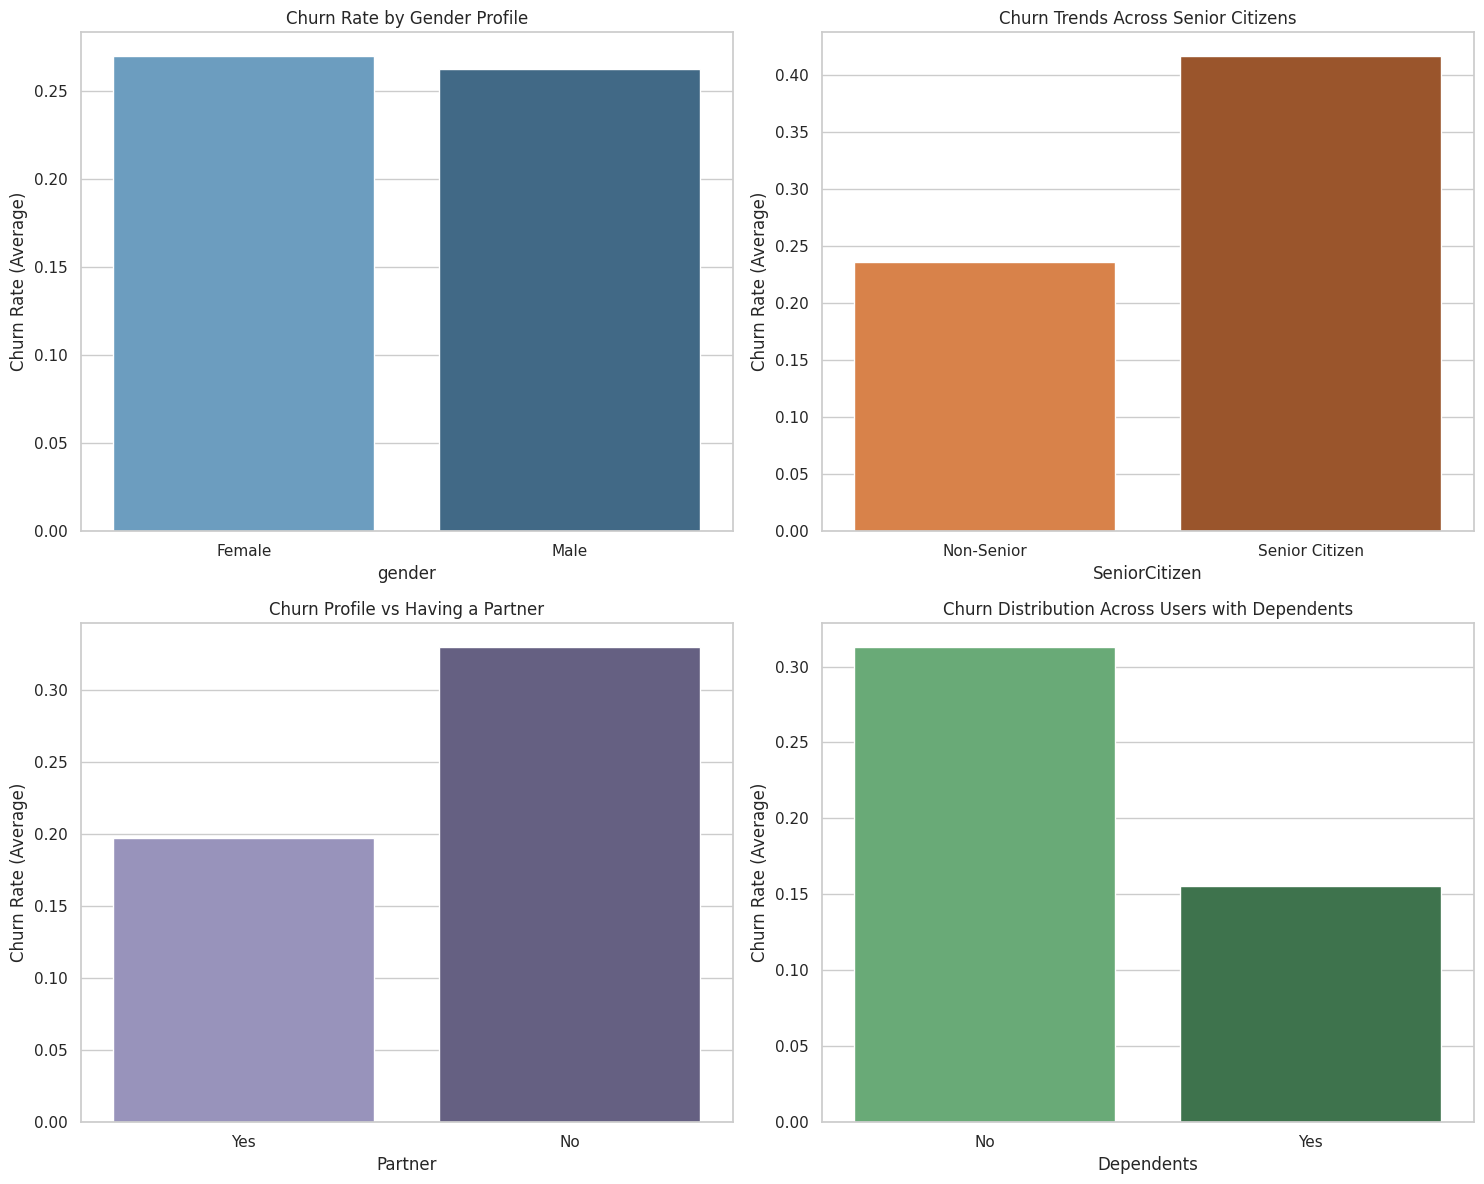

In [21]:
# Set up a 2x2 grid layout for demographic subplots
fig, axes = plt.subplots(2, 2, figsize=(15, 12))
sns.set_theme(style="whitegrid")

# 1. Gender distribution against churn
sns.barplot(x='gender', y='Churn', data=df, ax=axes[0, 0], errorbar=None, hue='gender', legend=False, palette='Blues_d')
axes[0, 0].set_title('Churn Rate by Gender Profile')
axes[0, 0].set_ylabel('Churn Rate (Average)')

# 2. SeniorCitizen and churn (0 = Younger, 1 = Senior)
sns.barplot(x='SeniorCitizen', y='Churn', data=df, ax=axes[0, 1], errorbar=None, hue='SeniorCitizen', legend=False, palette='Oranges_d')
axes[0, 1].set_title('Churn Trends Across Senior Citizens')
axes[0, 1].set_ylabel('Churn Rate (Average)')
axes[0, 1].set_xticks([0, 1])  # Explicitly sets the tick positions first
axes[0, 1].set_xticklabels(['Non-Senior', 'Senior Citizen'])

# 3. Partner with churn
sns.barplot(x='Partner', y='Churn', data=df, ax=axes[1, 0], errorbar=None, hue='Partner', legend=False, palette='Purples_d')
axes[1, 0].set_title('Churn Profile vs Having a Partner')
axes[1, 0].set_ylabel('Churn Rate (Average)')

# 4. Dependents with churn
sns.barplot(x='Dependents', y='Churn', data=df, ax=axes[1, 1], errorbar=None, hue='Dependents', legend=False, palette='Greens_d')
axes[1, 1].set_title('Churn Distribution Across Users with Dependents')
axes[1, 1].set_ylabel('Churn Rate (Average)')

plt.tight_layout()
plt.show()





• Gender: The churn rate between male and female customers is nearly identical, indicating that gender plays almost no role in whether a customer decides to leave the company.

• Senior Citizens: Older customers exhibit a significantly higher attrition risk, churning at nearly double the rate of the younger customer base.

• Partners & Dependents: Customers who have a partner or dependents are noticeably more stable and show much lower churn rates. This suggests that family units or multi-person households are more stable and less likely to cancel their subscriptions.


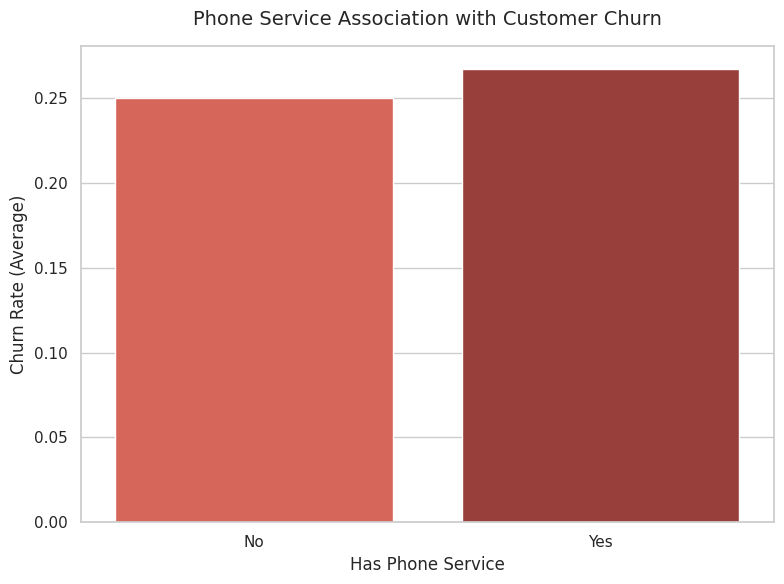

In [22]:
# Create canvas space for Service Analysis
plt.figure(figsize=(8, 6))
sns.set_theme(style="whitegrid")

# Plot Phone Service against Churn using modern Seaborn parameters
sns.barplot(x='PhoneService', y='Churn', data=df, errorbar=None, hue='PhoneService', legend=False, palette='Reds_d')

# Labels and layout titles
plt.title('Phone Service Association with Customer Churn', fontsize=14, pad=15)
plt.xlabel('Has Phone Service', fontsize=12)
plt.ylabel('Churn Rate (Average)', fontsize=12)

plt.tight_layout()
plt.show()


What the output shows: The average churn rate remains highly stable regardless of whether a customer subscribes to an active landline phone service.

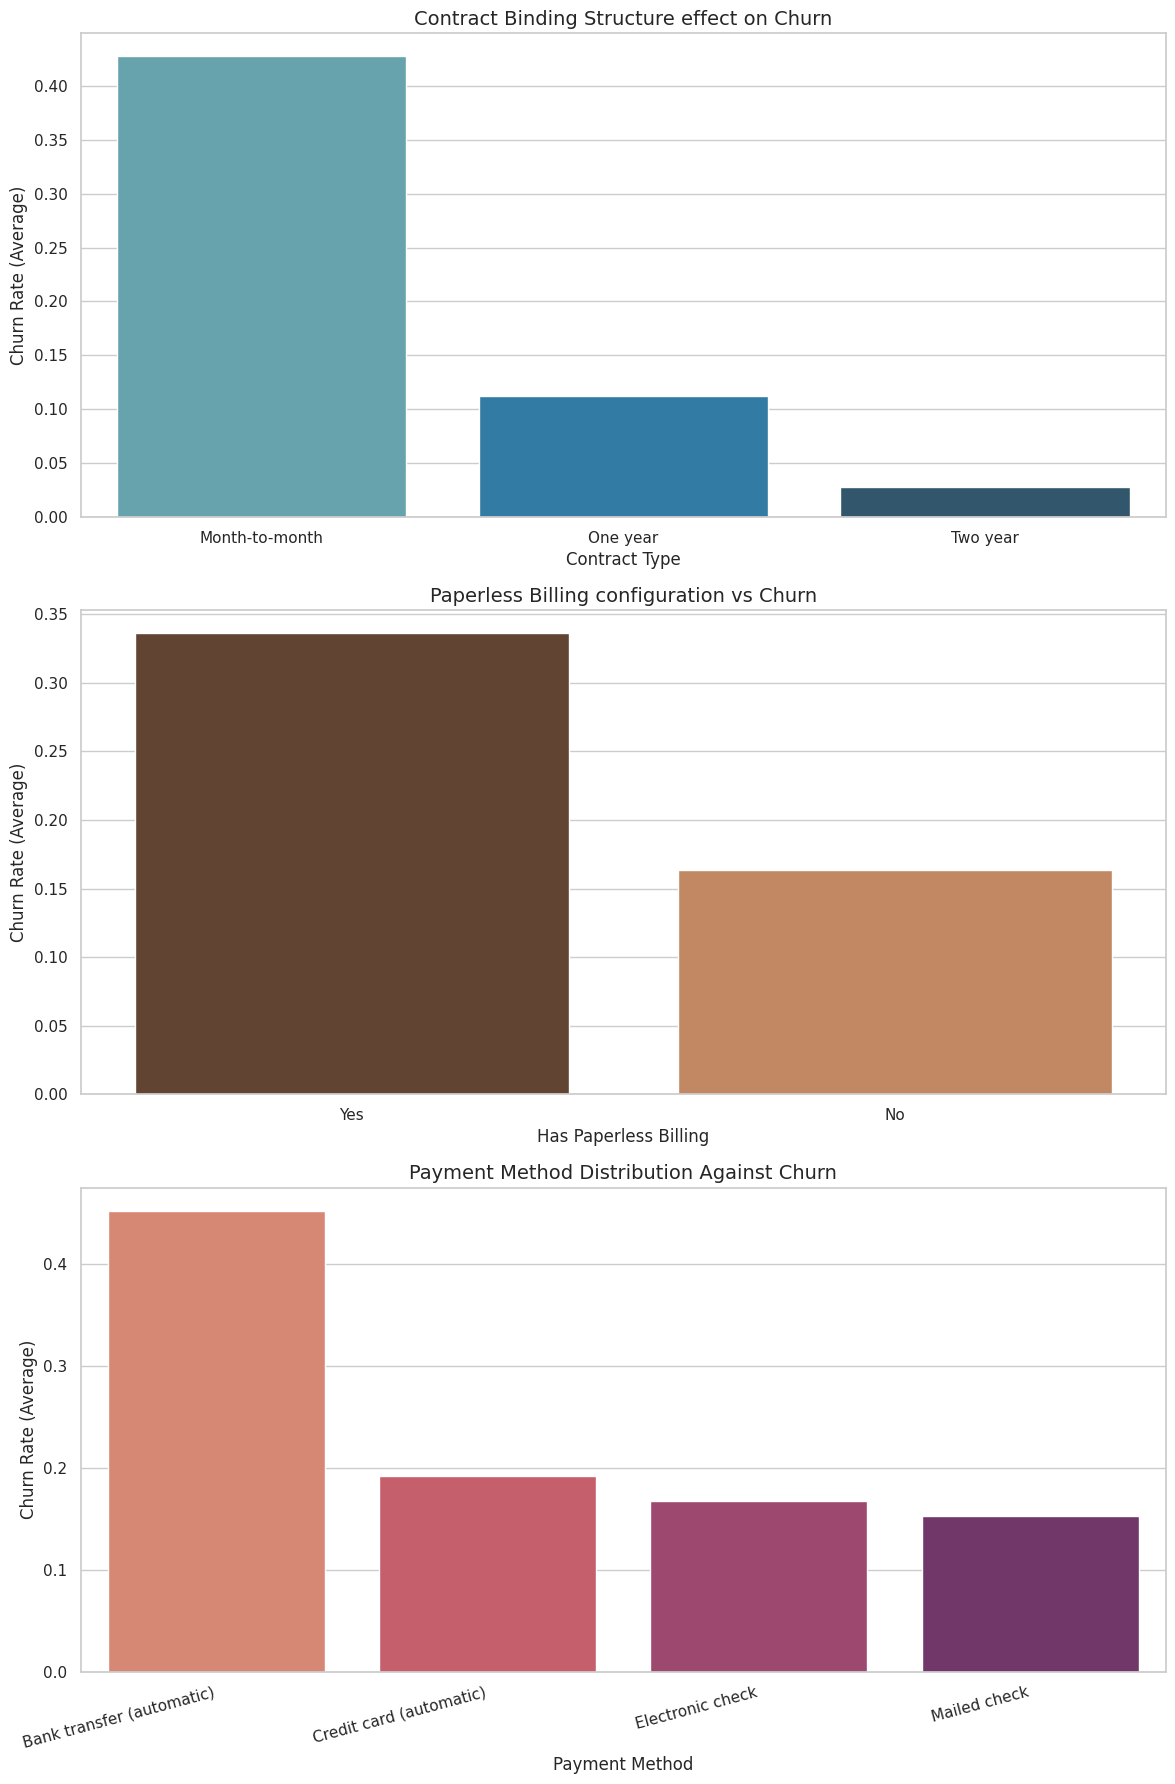

In [24]:
# Set up a layout for the 3 billing subplots
fig, axes = plt.subplots(3, 1, figsize=(12, 18))
sns.set_theme(style="whitegrid")

# 1. Contract type and churn
sns.barplot(x='Contract', y='Churn', data=df, ax=axes[0], errorbar=None, hue='Contract', legend=False, palette='YlGnBu_d')
axes[0].set_title('Contract Binding Structure effect on Churn', fontsize=14)
axes[0].set_ylabel('Churn Rate (Average)', fontsize=12)
axes[0].set_xlabel('Contract Type', fontsize=12)

# 2. Paperless billing and churn
sns.barplot(x='PaperlessBilling', y='Churn', data=df, ax=axes[1], errorbar=None, hue='PaperlessBilling', legend=False, palette='copper')
axes[1].set_title('Paperless Billing configuration vs Churn', fontsize=14)
axes[1].set_ylabel('Churn Rate (Average)', fontsize=12)
axes[1].set_xlabel('Has Paperless Billing', fontsize=12)

# 3. Payment method and churn
sns.barplot(x='PaymentMethod', y='Churn', data=df, ax=axes[2], errorbar=None, hue='PaymentMethod', legend=False, palette='flare')
axes[2].set_title('Payment Method Distribution Against Churn', fontsize=14)
axes[2].set_ylabel('Churn Rate (Average)', fontsize=12)
axes[2].set_xlabel('Payment Method', fontsize=12)

# FIX: Explicitly set the tick positions first to satisfy FixedLocator, then change/rotate labels
axes[2].set_xticks(range(len(df['PaymentMethod'].unique())))
axes[2].set_xticklabels(sorted(df['PaymentMethod'].unique()), rotation=15, ha='right')

plt.tight_layout()
plt.show()


• Contract Structure: Customers on Month-to-month contracts have an incredibly high churn rate compared to those on one-year or two-year commitments. Forcing long-term contract lock-ins is a major factor in improving retention.

• Paperless Billing: Customers who sign up for digital paperless statements leave at a higher rate than those who prefer traditional statement tracking methods.

• Payment Methods: Financial transactional clearings play a massive role in attrition behavior. Customers utilizing an Electronic Check system exit at a much higher average rate than users using automated credit cards, bank account clearings, or standard mailed physical paper checks.
